# IBM Lunar FM · кратеры · Colab v1
## Цель
Отдельный FP32-запуск **опубликованного NAC crater detector**, без обучения,
квантования и языковой модели. Из рамок по фиксированным правилам получаем Q1–Q4.
100 clean-снимков (50 Moon + 50 Mars), до 400 ответов. Пока **без научного scoring**.
Сначала 2 лунных val-снимка / 8 ответов, затем просмотр рамок. Полный прогон выключен.

**Начать в новой Colab VM с GPU T4.** Старый SpaceLLaVA notebook не запускать параллельно.
Загрузить `ibm_craters_v1.zip` в `MyDrive/planetary_benchmark/`.
Для первой установки задать `DOWNLOAD_WEIGHTS=True`, затем выполнять ячейки по порядку.
Веса ≈4.18 GB десятичных, плюс библиотеки и cache; желательно ≥25 GiB свободного диска
до установки. Достаточность 12.67 GB RAM / T4 пока не проверена на реальном GPU.

### Предположения и границы
- Используются те же PNG Q1–Q4 из `orbital_300_v4`; никаких масок/эталонов в ZIP.
- Grayscale → bilinear 256×256 → DN/255 → published NAC mean/std.
  Это объявленный PNG transfer protocol, не воспроизведение native TIFF/NPY.
- Разный исходный масштаб/камера и перенос на Марс требуют отдельного анализа.
- Score ≥0.5 фиксирован до прогона; grid, размер, край, tie — `crater-reference-v1`.
- Smoke success означает исполнение, **не** правильные ответы или чистый holdout.

Источники: [веса и NAC_config](https://huggingface.co/nasa-ibm-ai4science/Crater-Detection-NASA-IBM-Lunar-Foundation-Model/tree/f09ebeae2099c28f09bf4060f56d3e327a6192de),
[backbone](https://huggingface.co/nasa-ibm-ai4science/NASA-IBM-Lunar-Foundation-Model/tree/b657bdfe6fc4c0445d918f77a2d7b919805f3bce),
[runtime](https://github.com/NASA-IMPACT/NASA-IBM-Lunar-Foundation-Model/tree/d54c67aad513cb9daca444afa425cfb278e4fbf8).

## Настройка
### 1. Параметры и Drive
При resume сохранить RUN_ID и тот же ZIP; после новой VM снова сделать smoke. SESSION_ID на новой VM новый.

In [1]:
from pathlib import Path
import hashlib, json, os, shutil, stat, subprocess, sys, uuid, zipfile
from google.colab import drive
drive.mount('/content/drive')
PERSIST = Path('/content/drive/MyDrive/planetary_benchmark')
BUNDLE_ZIP = PERSIST/'ibm_craters_v1.zip'
WORKSPACE = Path('/content/planetary_ibm_craters_v1')
VENV = Path('/content/venv_ibm_craters_v1')
PYTHON = str(VENV/'bin/python')
RUN_ID = 'ibm_craters_v1_clean'
SESSION_ID = uuid.uuid4().hex
DOWNLOAD_WEIGHTS = True  # True при первой явной загрузке IBM weights/runtime
RUN_SMOKE = True
RUN_BENCHMARK = True
RESUME = False
PERSIST.mkdir(parents=True, exist_ok=True)
print('Session:', SESSION_ID, '| local disk GiB:', round(shutil.disk_usage('/content').free/2**30, 1))
subprocess.run(['nvidia-smi'], check=True)


Mounted at /content/drive
Session: 2c78f3cea44e49e980b444a7d4814072 | local disk GiB: 70.3


CompletedProcess(args=['nvidia-smi'], returncode=0)

### 2. Проверка и распаковка
ZIP проверяется до исполнения кода; старый workspace не перезаписывается.

In [2]:
EXPECTED_ZIP_SHA256 = '56fd5ea5a438bca4f23020e559305489fb0bc752f6ef13ea4a13612d15ddda54'
assert BUNDLE_ZIP.is_file(), f'Upload {BUNDLE_ZIP.name} to {PERSIST}'
assert hashlib.sha256(BUNDLE_ZIP.read_bytes()).hexdigest() == EXPECTED_ZIP_SHA256, 'Wrong/changed ZIP'
with zipfile.ZipFile(BUNDLE_ZIP) as archive:
    entries = archive.infolist()
    assert len(entries) < 700 and sum(e.file_size for e in entries) < 128*2**20
    assert len({e.filename for e in entries}) == len(entries)
    manifest = json.loads(archive.read('colab_bundle.json'))
    assert set(archive.namelist()) == set(manifest['files_sha256']) | {'colab_bundle.json'}
    for entry in entries:
        name = entry.filename
        path = Path(name)
        assert not path.is_absolute() and '..' not in path.parts and '\\' not in name and ':' not in name
        assert 'data_rover' not in [p.lower() for p in path.parts]
        assert not stat.S_ISLNK(entry.external_attr >> 16) and entry.file_size < 32*2**20
        data = archive.read(entry)
        if name != 'colab_bundle.json':
            assert hashlib.sha256(data).hexdigest() == manifest['files_sha256'][name]
        target = WORKSPACE/path
        assert target.resolve().is_relative_to(WORKSPACE.resolve())
        if target.exists():
            assert target.is_file() and target.read_bytes() == data, f'Changed workspace: {name}'
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(data)
assert (WORKSPACE/'requirements/ibm-crater-colab.txt').is_file()
print('Bundle:', manifest['selected_images'], 'images;', manifest['requests'], 'questions')


Bundle: 100 images; 400 questions


### 3. Изолированное окружение IBM
Python 3.12, Torch 2.12 + torchvision 0.27 **CUDA 13.0** (не PyPI CUDA 13.1).
Не изменяем SpaceLLaVA venv. Первый `pip` может занять несколько минут.
Kernel Colab не импортирует Torch; все model operations в отдельном Python.
Успешная установка ещё не подтверждает совместимость с драйвером T4.

In [3]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'uv==0.9.4'], check=True)
if not Path(PYTHON).is_file():
    subprocess.run([sys.executable, '-m', 'uv', 'venv', '--python', '3.12', '--seed', str(VENV)], check=True)
frozen = PERSIST/'environments'/RUN_ID/'requirements.freeze.txt'
constraints = WORKSPACE/'requirements/ibm-crater-colab.txt'
if RESUME:
    assert frozen.is_file(), 'No saved environment for this RUN_ID; start a new run instead'
    constraints = frozen
subprocess.run([PYTHON, '-m', 'pip', 'install', 'torch==2.12.0+cu130', 'torchvision==0.27.0+cu130',
    '--index-url', 'https://download.pytorch.org/whl/cu130'], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'install', '--only-binary=tokenizers', '-r', str(constraints)], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'check'], check=True)
env = dict(os.environ, PYTHONPATH=str(WORKSPACE/'src'), PYTHONUNBUFFERED='1',
           MPLBACKEND='Agg', HF_HUB_DISABLE_TELEMETRY='1')
frozen.parent.mkdir(parents=True, exist_ok=True)
actual_freeze = subprocess.check_output([PYTHON, '-m', 'pip', 'freeze'], text=True)
if not RESUME:
    if frozen.exists():
        assert frozen.read_text() == actual_freeze, 'Environment changed: choose a new RUN_ID'
    else:
        frozen.write_text(actual_freeze)
print('IBM Python:', PYTHON)


IBM Python: /content/venv_ibm_craters_v1/bin/python


### 4. Команды, логи и CUDA-проверка
Логи одновременно на экране и в Drive. Проверяем также CUDA NMS — он нужен детектору.

In [4]:
def step(command, *args):
    logs = PERSIST/'logs'
    logs.mkdir(exist_ok=True)
    log = logs/(RUN_ID+'_'+SESSION_ID[:8]+'_'+command+'.log')
    invocation = [PYTHON, '-m', 'planetary_vlm.colab_ibm', command, '--workspace', str(WORKSPACE), *map(str, args)]
    print('Log:', log)
    with log.open('a', encoding='utf-8') as stream:
        process = subprocess.Popen(invocation, cwd=WORKSPACE, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        try:
            for line in process.stdout:
                stream.write(line)
                stream.flush()
                print(line, end='')
            code = process.wait()
            if code:
                raise subprocess.CalledProcessError(code, invocation)
        except BaseException:
            if process.poll() is None:
                process.terminate()
                process.wait(timeout=30)
            raise
step('verify')
step('environment')


Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_craters_v1_clean_2c78f3ce_verify.log
{
  "images": 100,
  "bundle_sha256": "e1d09c3a445d48ff9d56df2beffd3c4f86e3a28dc6b43854f6cb24badf9d7b12"
}
Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_craters_v1_clean_2c78f3ce_environment.log
{
  "python": "3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]",
  "dependencies": {
    "torch": "2.12.0+cu130",
    "torchvision": "0.27.0+cu130",
    "terratorch": "1.2.13",
    "torchmetrics": "1.9.0",
    "lightning": "2.6.6",
    "numpy": "2.5.2",
    "Pillow": "12.3.0",
    "timm": "1.0.30",
    "einops": "0.8.2",
    "peft": "0.19.1",
    "transformers": "5.15.1",
    "huggingface-hub": "1.33.0",
    "pycocotools": "2.0.11",
    "PyYAML": "6.0.3"
  },
  "cuda": "13.0",
  "gpu": "Tesla T4",
  "gpu_total_bytes": 15637086208,
  "driver": "580.82.07",
  "capability": [
    7,
    5
  ],
  "cuda_arch_list": [
    "sm_75",
    "sm_80",
    "sm_86",
    "sm_90",
    "sm_100",
    "sm_120"

### 5. Опубликованные веса
Скачивание только при `DOWNLOAD_WEIGHTS=True`: backbone + NAC head, не датасеты и не WAC/IMP. Локальный cache VM теряется при её удалении.

In [5]:
step('assets', *(['--download'] if DOWNLOAD_WEIGHTS else []))


Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_craters_v1_clean_2c78f3ce_assets.log
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/planetary_ibm_craters_v1/external/IBM-Lunar/.git/
From https://github.com/NASA-IMPACT/NASA-IBM-Lunar-Foundation-Model
 * branch            d54c67aad513cb9daca444afa425cfb278e4fbf8 -> FETCH_HEAD
HEAD is now at d54c67a Merge pull request #11 from NASA-IMPACT/crater-demo
{
  "assets_available": true,
  "gpu_verified": false,
  "options": {
    "runtime_repo": "/content/planeta

## Проверки
### 6. Smoke · 2 lunar val images
Одна загрузка модели, два независимых изображения, четыре ответа из каждой группы рамок.
`moon_seg_002`, `moon_seg_012` — старые dev-контроли; **правильные ответы не передаются**.
Рамки ≥0.5 зелёные (eligible) / оранжевые (исключены геометрическими правилами).
Если рамки странные или отсутствуют на очевидных кратерах, **полный прогон пока не включать**:
прислать ZIP smoke + log. Успешный smoke сам по себе не тест точности.

Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_craters_v1_clean_132126ce_smoke.log
{"event": "ibm_loading", "precision": "float32", "quantization": null}
/content/venv_ibm_craters_v1/lib/python3.12/site-packages/terratorch/tasks/object_detection_task.py:85: UserWarning: The Object Detection Task has to be considered experimental. This is less mature than the other tasks and being further improved.
  warnings.warn(
LunarBackbone: loaded modality info (20 modalities: ['aspect', 'aspect_3m', 'dtm', 'dtm_3m', 'metadata', 'nac', 'slope', 'slope_3m', 'static_maps', 'tok_aspect', 'tok_aspect_3m', 'tok_dtm', 'tok_dtm_3m', 'tok_nac', 'tok_slope', 'tok_slope_3m', 'tok_uv', 'tok_vis', 'uv', 'vis'])
encoder_embeddings.aspect.mod_emb
encoder_embeddings.aspect.pos_emb
encoder_embeddings.aspect.proj.weight
encoder_embeddings.aspect_3m.mod_emb
encoder_embeddings.aspect_3m.pos_emb
encoder_embeddings.aspect_3m.proj.weight
encoder_embeddings.dtm.mod_emb
encoder_embeddings.dtm.pos_emb
encoder_em

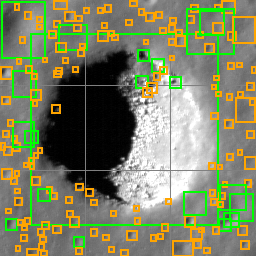

moon_seg_012 {'crater_presence_v1': 'YES', 'crater_center_v1': 'NO', 'crater_largest_location_v1': '1', 'crater_half_count_v1': 'LEFT'}


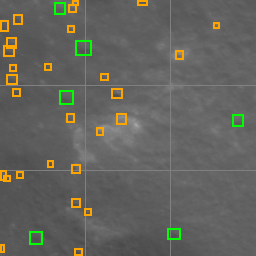

In [11]:
if RUN_SMOKE:
    step('smoke', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID)
    from IPython.display import display
    from PIL import Image
    smoke_folder = WORKSPACE/'outputs/IBM-Craters'/(RUN_ID+'_smoke_'+SESSION_ID[:8])
    for path in sorted((smoke_folder/'overlays').glob('*.png')):
        record = json.loads((smoke_folder/'detections'/(path.stem+'.json')).read_text())
        print(path.stem, record['answers'])
        display(Image.open(path))
else:
    print('Smoke disabled; benchmark is gated until a real successful smoke in this session')


In [10]:
import uuid

SESSION_ID = uuid.uuid4().hex
RUN_PILOT = True
print("Новый SESSION_ID:", SESSION_ID)

Новый SESSION_ID: 132126ce5561472aaf10f4bce2030ca0


## Следующий шаг
### 7. Полный clean-прогон · отдельно включить после просмотра smoke
В следующей ячейке заменить `RUN_BENCHMARK=False` на `True`, не перезапуская parameters.
50 Moon + 50 Mars → 100 model forwards → 400 label answers. Искажений пока нет.
Результат после каждого снимка сохраняется в Drive; для batch resume установить RESUME=True
в parameters, повторить setup/assets/**новый smoke**, затем run. Для повторного smoke
создать новый SESSION_ID, старые результаты не удалять.
При смене dependencies/ZIP/input protocol нужен новый RUN_ID, не принудительный resume.

In [ ]:
RUN_BENCHMARK = False  # Изменить здесь только после визуальной проверки smoke
if RUN_BENCHMARK:
    step('run', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID,
         *(['--resume'] if RESUME else []))
else:
    print('Full run disabled. First inspect smoke overlays.')
print('Results and ZIP:', PERSIST/'runs/IBM-Craters', 'and', PERSIST)


### Что прислать
Сначала `<RUN_ID>_smoke_<SESSION_ID[:8]>_results.zip` из `MyDrive/planetary_benchmark/`.
При сбое — соответствующий `.log` из `logs/` и smoke ZIP, если он успел появиться.
В архиве оригиналы, overlays, boxes/scores, Q1–Q4, версии и хэши. Метрик accuracy пока нет:
допуск эталонов и training-overlap остаются отдельным этапом. **Запуск GPU локально не проверен**.